# 02-开发环境准备与FreeRTOS源码导入


## 1. 本篇内容与学习目标

本篇对应《FreeRTOS 从入门到实战》的 `03freeRTOS环境准备.pptx` 和 `04项目导入freeRTOS库.pptx`，是十七篇笔记中的第 **02** 篇。先认识源码版本和目录，再把课程需要的内核文件、移植文件及配置头文件引入已有工程。

| 课程内容 | 本篇要解决的问题 |
|---|---|
| 源码获取与版本选择 | 从哪里获取源码，复现课程时选择哪个版本？ |
| 源码目录与核心文件 | 哪些文件负责内核功能，哪些文件与硬件平台有关？ |
| GD32 的移植层选择 | 怎样按处理器架构和编译器选择 `port.c`、`portmacro.h`？ |
| 工程准备与源码裁剪 | 从怎样的基础工程开始，需要保留哪些源码？ |
| 配置与 IDE 集成 | `FreeRTOSConfig.h` 放在哪里，编译文件和头文件路径怎样加入？ |

本篇的目标是把源码和工程结构准备清楚。时钟、中断适配及多任务运行验证由第03篇继续展开。


## 2. 获取源码与选择课程版本

课件提供的源码入口是 [FreeRTOS 官网](https://www.freertos.org/)，推荐使用 **2022 年 10 月的 LTS 发布包**，文件名为：

```text
FreeRTOSv202210.01_LTS.zip
```

LTS 是 **Long Term Support（长期支持）**。课件建议固定课程版本，减少使用更新版本时因文件、接口或配置差异产生的兼容问题。

复现课程时，先按课件取得这一发布包，解压后确认内核源码和移植目录齐全，再复制需要的文件到工程中。保留原始解压资料，后续裁剪只针对工程里的副本。

> 版本说明：这里记录的是课程复现建议。旧版本的 LTS 名称不表示它在当前日期仍处于支持期；维护新项目时还需要另行确认版本的支持状态。本篇沿用课件版本路线。


## 3. 认识原始源码目录

课件先区分基础内核与扩展组件。理解目录职责后，导入工程时就能知道哪些文件是当前课程需要的。

```text
解压后的发布包/
├── FreeRTOS/
│   └── Source/
│       ├── include/       # 内核公共头文件
│       ├── portable/      # 处理器、编译器相关的移植文件及内存管理方案
│       ├── tasks.c
│       ├── queue.c
│       ├── list.c
│       └── ...其他内核源文件
└── FreeRTOS-Plus/          # 扩展组件
```

| 原始目录 | 主要内容 | 在本课程中的用途 |
|---|---|---|
| `FreeRTOS/Source/` | 内核 `.c` 文件及相关子目录 | 作为任务、通信等内核功能的源码基础 |
| `FreeRTOS/Source/include/` | `FreeRTOS.h`、`task.h`、`queue.h` 等公共头文件 | 为内核和应用提供类型、配置入口及接口声明 |
| `FreeRTOS/Source/portable/` | 不同编译器、CPU 架构的端口和 `MemMang` | 选择与目标平台对应的端口及一种内存管理方案 |
| `FreeRTOS-Plus/` | TCP/IP、MQTT、CLI 等扩展 | 当前内核入门工程不需要全部导入 |

`Source` 中的通用内核代码可以跨平台复用；直接涉及寄存器、汇编和上下文切换的部分，则通过 `portable` 适配目标平台。


## 4. 核心源文件与公共头文件

课件按文件说明内核的主要职责。后续查看源码时，可以先由功能定位文件，再阅读具体接口。

| 文件 | 主要职责 |
|---|---|
| `tasks.c` | 任务创建、调度和任务状态管理 |
| `queue.c` | 队列通信；信号量等机制也依赖其中的实现 |
| `list.c` | 内核链表操作，为调度等功能提供基础 |
| `timers.c` | 软件定时器及定时器服务 |
| `event_groups.c` | 事件组及事件位管理 |
| `stream_buffer.c` | 流缓冲区与消息缓冲区的实现 |
| `croutine.c` | 协程（Co-routine）实现，课件工程截图中也包含此文件 |

公共头文件位于 `Source/include/`，本课先认识三个入口。

| 头文件 | 用途 |
|---|---|
| `FreeRTOS.h` | 内核公共定义，并引入工程配置与平台相关定义 |
| `task.h` | 任务管理接口 |
| `queue.h` | 队列接口 |

导入时保留 `include/` 下的全部头文件，不只复制这三个文件，避免遗漏内核及其他接口需要的声明。

> 源码核对：课件把缓冲区文件写为 `stream_buffer.c / message_buffer.c`。核对官方 [FreeRTOS-Kernel V10.5.1 源码](https://github.com/FreeRTOS/FreeRTOS-Kernel/tree/V10.5.1) 后，消息缓冲区的接口在 `include/message_buffer.h`，实现基于 `stream_buffer.c`，没有独立的 `message_buffer.c`。导入时按实际文件复制，不需要寻找或新建这个 `.c` 文件。


## 5. portable的作用与GD32端口选择

### 5.1 为什么需要移植层

不同处理器保存寄存器、处理中断和控制临界区的方式不同。FreeRTOS 把这些相关实现放在 `portable/` 中，使通用内核与平台相关部分分开。

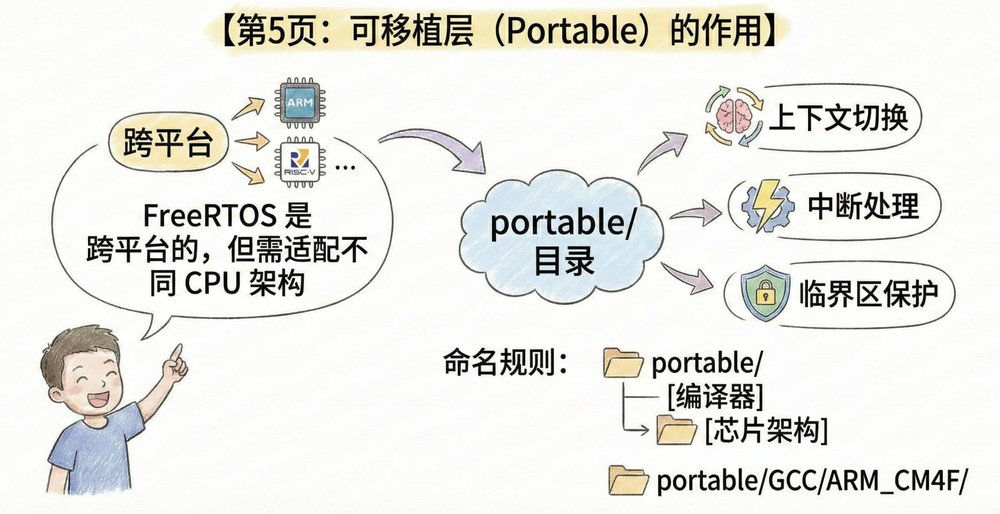

*来源：`03freeRTOS环境准备.pptx` 第7页，裁去页眉页脚。*

课件强调移植层的三项职责。

| 职责 | 在内核运行中的作用 |
|---|---|
| 上下文切换 | 保存当前任务的运行现场，恢复下一任务的运行现场 |
| 中断处理 | 将处理器的中断机制与内核调度配合起来 |
| 临界区保护 | 为不能被相关中断打断的操作提供平台相关支持 |

目录通常按“编译器 → 芯片架构”组织，例如：

```text
portable/[编译器]/[芯片架构]/
portable/GCC/ARM_CM4F/
```

### 5.2 课程选择的端口

课件以带浮点单元 FPU 的 Cortex-M4，也就是 **Cortex-M4F**，说明 GD32 工程的端口选择，并采用以下路径：

```text
FreeRTOS/Source/portable/GCC/ARM_CM4F/
├── port.c
└── portmacro.h
```

| 文件 | 课件说明的内容 |
|---|---|
| `port.c` | 上下文切换、`PendSV` 以及 `SysTick` 等平台相关处理 |
| `portmacro.h` | 平台类型、内联汇编和临界区等相关宏定义 |

复制时，`port.c` 与 `portmacro.h` 应来自同一端口目录。编译器目标、CPU 架构和 FPU 设置也要与该端口匹配。

> 工具链说明：课件将 `GCC/ARM_CM4F` 作为 GCC 及 Keil AC6 工程的选取路径。Keil 是 IDE，AC6 使用的是 `armclang`，并不等于 GCC；实际使用时仍须核对编译器版本和端口支持情况，不能只根据 IDE 名称选择文件。此端口源码会检查硬件浮点支持，相关编译设置需要与 Cortex-M4F 相符。

课件还提示避免使用旧的 RVDS 端口。这个提示应结合课程的 AC6/GCC 环境理解：RVDS 对应旧 ARM Compiler 5 工具链，官方源码中仍有这一目录，不能概括为所有 Keil 工程都不允许使用。当前工程按已选定的工具链使用对应端口，避免混用。


## 6. 最小工程组成与IDE分组

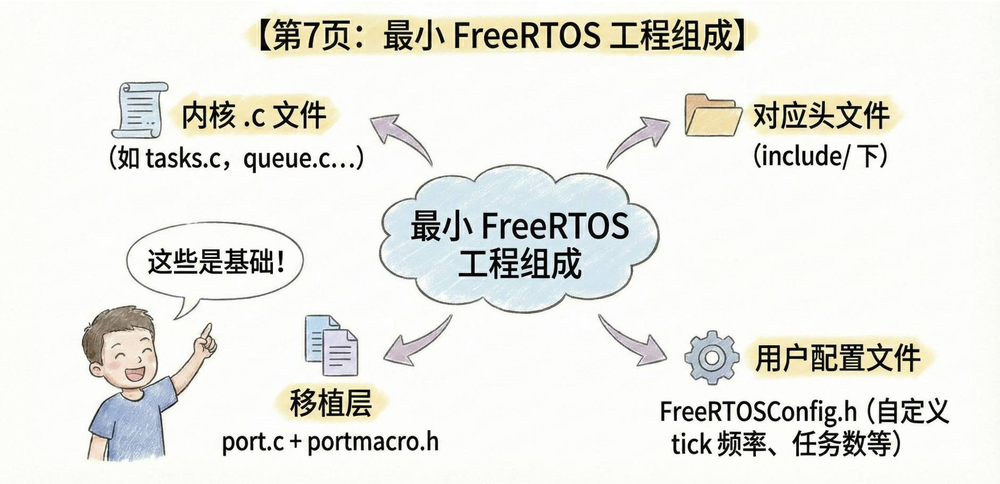

*来源：`03freeRTOS环境准备.pptx` 第9页，裁去页眉页脚。图中的配置描述为概览，具体宏含义见第10节。*

课件把引入内核所需的基础部分归纳为四类。

| 组成 | 要准备的文件 | 为什么需要 |
|---|---|---|
| 内核源码 | `tasks.c`、`queue.c`、`list.c` 等 | 实现任务和内核功能 |
| 公共头文件 | `Source/include/` 下的文件 | 提供接口与类型定义 |
| 移植层 | 选定端口的 `port.c`、`portmacro.h` | 适配 CPU 和工具链 |
| 工程配置 | `FreeRTOSConfig.h` | 设置节拍、优先级、内存和功能开关 |

本课后面的工程导入还选择 `heap_4.c`，作为动态内存管理实现。它与处理器端口都是需要加入工程编译的文件。

课件展示的 Keil 工程将文件分成 `FreeRTOS_Core` 和 `FreeRTOS_Port` 两个组。

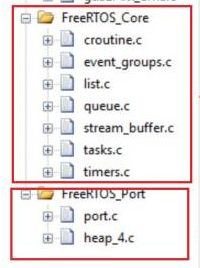

*来源：`03freeRTOS环境准备.pptx` 第10页，仅保留内核与移植相关工程组。*

```text
FreeRTOS_Core
├── croutine.c
├── event_groups.c
├── list.c
├── queue.c
├── stream_buffer.c
├── tasks.c
└── timers.c

FreeRTOS_Port
├── port.c
└── heap_4.c
```

工程组用于在 IDE 中组织参与编译的文件，不必与磁盘上的文件夹完全同名。头文件能否找到，仍由实际存放位置和头文件搜索路径决定。


## 7. FreeRTOS的MIT许可

`04项目导入freeRTOS库.pptx` 先说明 FreeRTOS 的开源许可，便于理解为什么可以把源码引入自己的工程。

课件强调 MIT 许可允许使用、修改、商用，并允许把内核用于闭源产品。因此，应用项目可以按自身需要使用和调整内核源码。

> 许可补充：依据官方 [MIT 许可文本](https://github.com/FreeRTOS/FreeRTOS-Kernel/blob/V10.5.1/LICENSE.md)，分发软件副本或其重要部分时，需要保留版权和许可声明；软件按 “AS IS” 提供，不附带担保。课件图中“无法律风险”不能作为无条件结论，BSD 也属于宽松许可，不能与 GPL 的 copyleft 要求一概而论。

复制源码进工程时，一并保留对应的版权和许可说明。


## 8. 从可运行的裸机工程开始

移植前先选用已经验证能够运行的基础工程。这样出现问题时，能够集中检查新引入的内核和移植配置，减少基础驱动、启动配置与内核问题混在一起的情况。

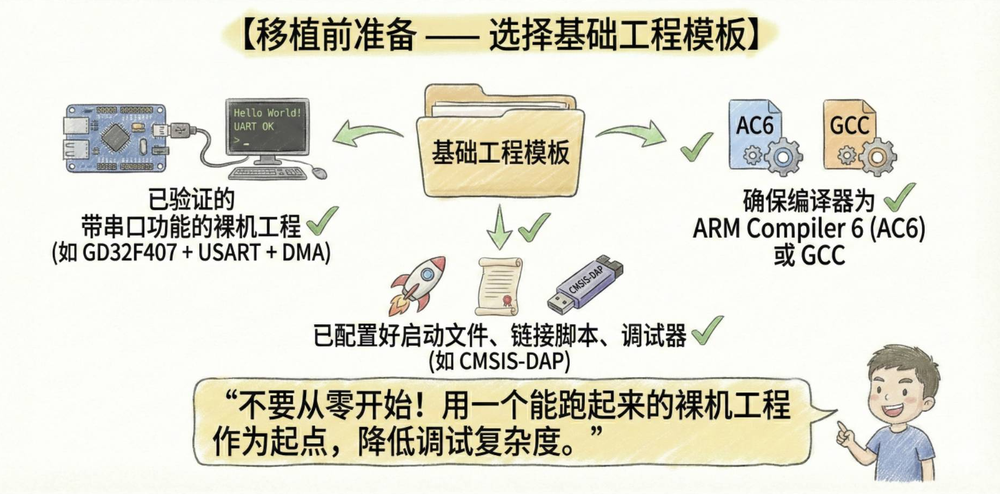

*来源：`04项目导入freeRTOS库.pptx` 第5页，裁去页眉页脚。*

课件用 `GD32F407 + USART + DMA` 作为示例，并列出以下准备条件。

| 准备项 | 移植前应确认的状态 |
|---|---|
| 裸机工程 | 能编译、下载并在开发板上运行 |
| 串口功能 | 已有可观察的输出，用于判断基础程序是否正常 |
| 编译器 | 已明确使用 ARM Compiler 6（AC6）或 GCC，并与后续端口选择对应 |
| 启动文件 | 已按目标芯片配置好 |
| 链接配置 | 已有正确的链接脚本或 Keil 散点配置 |
| 调试器 | 已配置，例如课件中的 CMSIS-DAP |

图中的 `Hello World!`、`UART OK` 表示裸机串口已经正常工作的示意，不是本篇实际运行得到的输出。

操作顺序是：先验证原裸机工程，再在工程副本中加入 FreeRTOS。基础工程能运行后，才开始源码裁剪、配置和 IDE 导入。


## 9. 裁剪源码并组织工程目录

### 9.1 本课保留哪些文件

发布包面向多种平台，当前工程只需要选定平台的内容。课件要求保留以下四部分。

| 原始资料中的位置 | 复制到工程的内容 |
|---|---|
| `FreeRTOS/Source/` | 该目录直接包含的所有内核 `.c` 文件 |
| `FreeRTOS/Source/include/` | 全部公共头文件 |
| `FreeRTOS/Source/portable/GCC/ARM_CM4F/` | 课程选定端口的 `port.c`、`portmacro.h` |
| `FreeRTOS/Source/portable/MemMang/heap_4.c` | 本课采用的动态内存管理实现 |

其他 CPU 和编译器端口、未使用的 `FreeRTOS-Plus` 扩展不加入当前目标工程。原始发布包保留完整，工程副本只复制需要的文件。

> **同一个工程只编译一种 `heap_x.c`。** 本课选择 `heap_4.c`，不要再把 `heap_1.c`、`heap_2.c` 等同时加入编译，否则会产生相同内存接口的重复定义。

### 9.2 课件中的分层结构

课件先展示裁剪后的 `Source/`、`Portable/`、`Config/`，再把这一结构放入整个工程的中间件目录。

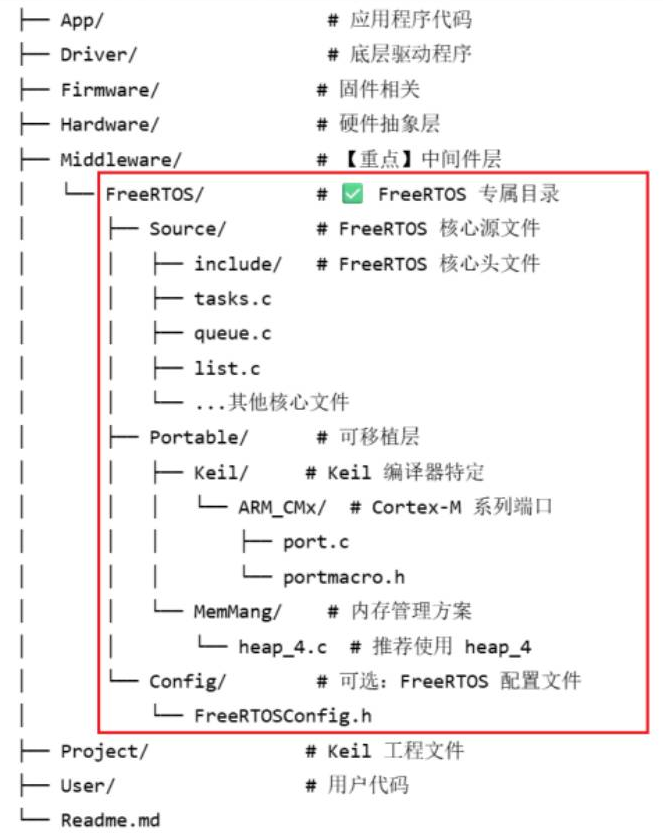

*来源：`04项目导入freeRTOS库.pptx` 第11页，仅保留目录图。图中 `Keil/ARM_CMx` 是概念性端口示意，实际端口按第5节选择。*

这一分层把应用、驱动、固件、硬件抽象、中间件和工程文件分开。FreeRTOS 放进 `Middleware/`，内部再区分通用源码、移植层与配置。

下面保留课件的分层方式，将端口目录落实为前面选定的 `GCC/ARM_CM4F`。这是**整理后的工程副本目录**，与发布包原始目录中 `Source/portable/` 的位置不同。

```text
工程根目录/
├── App/                              # 应用程序
├── Driver/                           # 底层驱动
├── Firmware/                         # 固件相关
├── Hardware/                         # 硬件抽象
├── Middleware/
│   └── FreeRTOS/
│       ├── Source/
│       │   ├── include/              # 公共头文件
│       │   ├── croutine.c
│       │   ├── event_groups.c
│       │   ├── list.c
│       │   ├── queue.c
│       │   ├── stream_buffer.c
│       │   ├── tasks.c
│       │   └── timers.c
│       ├── Portable/
│       │   ├── GCC/
│       │   │   └── ARM_CM4F/
│       │   │       ├── port.c
│       │   │       └── portmacro.h
│       │   └── MemMang/
│       │       └── heap_4.c
│       └── Config/
│           └── FreeRTOSConfig.h
├── Project/                          # Keil工程文件
├── User/                             # 用户代码
└── Readme.md
```

原图中的 `ARM_CMx` 表示 Cortex-M 系列端口的概念占位，不能把它当作当前芯片的真实目录。磁盘目录可以按工程组织，但选择和复制的端口文件必须明确。


## 10. FreeRTOSConfig.h与典型配置

### 10.1 工程配置头文件的作用

`FreeRTOSConfig.h` 是应用工程提供给内核的配置头文件。内核通过它确定系统行为，并启用或关闭部分功能。

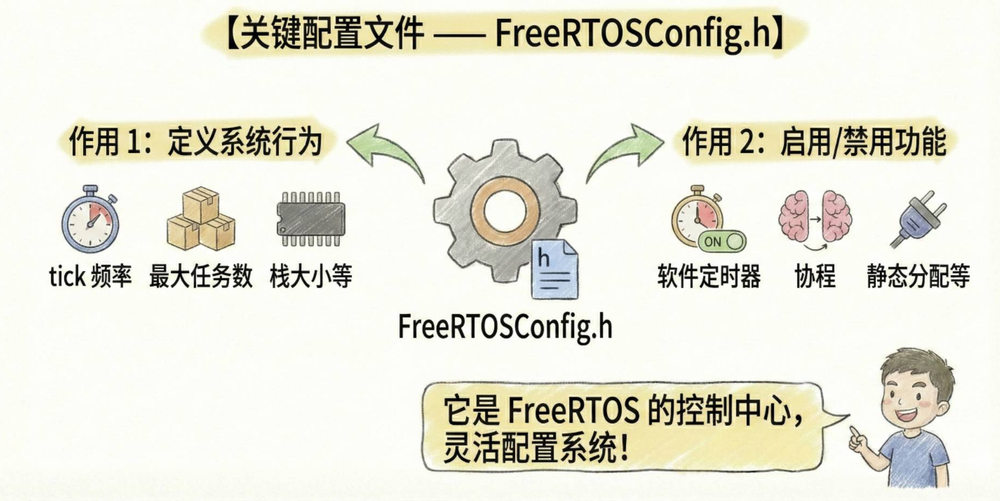

*来源：`04项目导入freeRTOS库.pptx` 第8页，裁去页眉页脚。图中“最大任务数”的表述需结合下表修正。*

| 配置类别 | 课件列出的内容 |
|---|---|
| 系统行为 | tick 频率、优先级级数、栈和堆等参数 |
| 功能开关 | 软件定时器、协程、静态内存分配等 |

在上节目录中，这个文件位于 `Middleware/FreeRTOS/Config/FreeRTOSConfig.h`，其所在目录也需要加入头文件搜索路径。整理源码时应同时准备与课程工程匹配的配置文件；仅把内核 `.c` 复制进来还不完整。

### 10.2 课件给出的四个配置宏

课件用以下片段说明典型配置值。这里按原值记录，**它只是配置片段，不是完整的 `FreeRTOSConfig.h`**。

```c
#define configTICK_RATE_HZ        (1000)
#define configMAX_PRIORITIES      (5)
#define configMINIMAL_STACK_SIZE  (128)
#define configTOTAL_HEAP_SIZE     ((size_t)(40*1024))
```

| 配置宏 | 示例值的含义 | 容易误解的地方 |
|---|---|---|
| `configTICK_RATE_HZ` | 每秒 1000 个 tick，名义节拍间隔为 1 ms | 不保证应用任务每 1 ms 必然执行一次 |
| `configMAX_PRIORITIES` | 提供 5 个任务优先级：0、1、2、3、4 | **是优先级级数，不是最多创建 5 个任务** |
| `configMINIMAL_STACK_SIZE` | 最小任务栈深度，空闲任务使用这个配置 | 单位是栈元素；不自动决定每个应用任务的栈大小 |
| `configTOTAL_HEAP_SIZE` | 为本课 `heap_4.c` 配置 40960 字节，即 40 KiB 的动态堆 | 不是芯片全部 RAM，也不能脱离实际 RAM 布局照搬 |

> 单位核对：任务栈深度使用 words，而非 bytes。官方 Cortex-M4F 端口的 `StackType_t` 是 `uint32_t`，因此这里的 128 个栈元素约为 512 字节。应用任务创建时仍要指定自身需要的栈深度。

这个配置文件把通用内核与具体工程的资源和功能需求连接起来。其他必需配置、时钟与中断相关设置在后续移植课件中继续处理。


## 11. 在IDE中导入源码与头文件路径

文件已经复制到磁盘后，还要让 IDE 知道哪些 `.c` 参与编译，以及从哪里查找头文件。这两类设置分别完成。

### 11.1 添加参与编译的文件

按课件的两个工程组组织：

1. 在 `FreeRTOS_Core` 中加入 `Source/` 下的七个内核 `.c` 文件。
2. 在 `FreeRTOS_Port` 中加入选定端口的 `port.c` 和 `MemMang/heap_4.c`。
3. 检查工程中只保留一个平台端口和一种 `heap_x.c` 参与编译。

公共头文件、`portmacro.h` 和 `FreeRTOSConfig.h` 由源码包含，通过头文件搜索路径定位。

### 11.2 设置头文件搜索路径

采用第9节的目录时，需要加入以下三个目录。这里先以工程根目录为参照列出逻辑路径：

```text
Middleware/FreeRTOS/Source/include
Middleware/FreeRTOS/Portable/GCC/ARM_CM4F
Middleware/FreeRTOS/Config
```

| 搜索目录 | 应能找到的头文件 |
|---|---|
| `Middleware/FreeRTOS/Source/include` | `FreeRTOS.h`、`task.h`、`queue.h` 等 |
| `Middleware/FreeRTOS/Portable/GCC/ARM_CM4F` | `portmacro.h` |
| `Middleware/FreeRTOS/Config` | `FreeRTOSConfig.h` |

如果 Keil 工程文件位于 `Project/`，且路径以工程文件所在目录为基准，则设置为：

```text
../Middleware/FreeRTOS/Source/include
../Middleware/FreeRTOS/Portable/GCC/ARM_CM4F
../Middleware/FreeRTOS/Config
```

设置后核对每条路径是否能到达真实文件，目录名称和层级应与磁盘一致。

> 路径说明：课件第10页另用 `Middlewares/FreeRTOS/core`、`Middlewares/FreeRTOS/port`、`Middlewares/FreeRTOS/port/GCC/ARM_CM4F` 演示导入，与后面的 `Middleware/FreeRTOS/Source` 分层不同。这些是不同组织示例，不能直接混用；头文件路径始终指向当前工程实际存放相应 `.h` 文件的目录。

### 11.3 课件提醒的两类常见错误

| 编译现象 | 优先检查 | 对应处理 |
|---|---|---|
| 找不到 `FreeRTOS.h` 等头文件 | 是否复制了 `include/`，搜索路径是否指向真实目录，相对路径基准是否正确 | 补齐文件并修正对应头文件路径 |
| 内存分配接口重复定义 | 是否把多个 `heap_x.c` 同时加入编译 | 当前工程只保留本课选用的 `heap_4.c` |

同样要确认 `portmacro.h` 和 `FreeRTOSConfig.h` 能被找到。完成这些步骤后，源码、配置与 IDE 设置应能一一对应；完整移植是否成功，还需要后续的时钟、中断和任务运行验证。


## 12. 课件小结与后续移植

两份课件的主线是：固定课程源码版本，认识内核与移植层，再从可运行的裸机工程开始，复制必要源码、配置 `FreeRTOSConfig.h`，最后加入编译文件和头文件路径。

按课件完成本篇准备时，工程中应能对应找到以下内容。

| 准备结果 | 对应文件或设置 |
|---|---|
| 内核源码齐全 | 七个内核 `.c` 文件及 `include/` 下的公共头文件 |
| 端口选择明确 | 与处理器和工具链匹配的 `port.c`、`portmacro.h` |
| 内存方案唯一 | 本课使用的 `heap_4.c` |
| 配置入口完整 | 工程自己的 `FreeRTOSConfig.h`，而非只有四个示例宏 |
| IDE 与磁盘目录对应 | 已加入源码，头文件路径指向真实文件夹 |

课件用最小化、模块化、可配置概括工程组织原则：保留当前平台需要的内容，分开管理内核、端口与配置，让目录和编译设置保持一致。

下一篇 **03-FreeRTOS移植、配置与多任务验证**，继续处理时钟、中断适配和任务运行。本篇记录源码准备与导入步骤，不包含硬件编译或运行验证结果。
